# 008 Hard — Out of distribution in density

Trajectory signature, trained on `P_max` below 6,528.6 Pa only; the deliverable is the in-range vs above-cut gap.

## Setup

In [1]:
from xgboost import XGBRegressor  # before torch (OpenMP clash on macOS)

import copy
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, train_test_split
from sklearn.multioutput import MultiOutputRegressor
from sklearn.preprocessing import StandardScaler

from pallas_score import normalised_to_physical, physical_to_normalised, score_submission
from physics_formulas import electrons_background, energy_gain_MeV, m3_to_cm3, species_B

torch.set_num_threads(1)

PACK = "/Users/netanmangal/Documents/netanmangal/ganil-artifact-hackathon-2026/challenges/surrogate-models/full-data"
TASK = "ood"
TARGETS = ['E_MeV', 'q_pC', 'dE_pct', 'emit_um', 'div_mrad', 'sigz_um']
FEATURES = ['P_max', 'cN2_max', 'L_inj', 'dip_frac', 'x_of', 'z_mm']
EPOCHS = 40
BATCH = 512
XGB_TREES = 300
HIDDEN = [256, 512, 64]
LOSS = nn.HuberLoss()
EPOCHS_RES = 60


def add_physics(frame):
    frame = frame.copy()
    frame["dz"] = frame.z_mm - (frame.L_inj + 3.2)
    frame["in_plasma"] = (frame.dz <= 0).astype(float)
    frame["n_e"] = frame.P_max * (1 - 0.3 * frame.cN2_max)
    frame["n_N2"] = frame.P_max * frame.cN2_max
    frame["gain"] = 0.0
    for config, rows in frame.groupby("config"):
        row = rows.iloc[0]
        z = np.linspace(0, (row.L_inj + 3.2) * 1e3, 500)
        n_He, n_N = species_B(z, row.P_max, row.cN2_max, row.L_inj, row.dip_frac)
        n_e = m3_to_cm3(electrons_background(n_He, n_N))
        gain = energy_gain_MeV(z, n_e, eta=0.27)
        frame.loc[rows.index, "gain"] = np.interp(rows.z_mm * 1e3, z, gain)
    return frame


def features(frame):
    return frame[FEATURES + ["dz", "in_plasma", "n_e", "n_N2", "gain"]].to_numpy()


def targets(frame):
    columns = []
    for t in TARGETS:
        columns.append(physical_to_normalised(t, frame[t]))
    return np.column_stack(columns)


def physical(pred):
    out = pd.DataFrame()
    for i, t in enumerate(TARGETS):
        out[t] = normalised_to_physical(t, pred[:, i])
    return out


def score(pred, frame, zone=None):
    pred = physical(pred)
    pred.insert(0, "z_mm", frame.z_mm.to_numpy())
    pred.insert(0, "config", frame.config.to_numpy())
    return score_submission(pred, frame[["config", "z_mm", "L_inj"] + TARGETS], zone=zone)


ood = json.load(open(f"{PACK}/pack_reference.json"))["sections"]["ood_split"]
CUT = ood["threshold"]
full = add_physics(pd.read_parquet(f"{PACK}/campaign_B_trajectories.parquet"))
data = full[full.config.isin(ood["train"])]
above = full[full.P_max >= CUT]
print(f"cut at P_max {CUT:.1f} Pa: {data.config.nunique()} training configs below, {above.config.nunique()} public configs above")
test_inputs = add_physics(pd.read_parquet(f"{PACK}/test_trajectory.parquet"))
configs = data.config.unique()

train_configs, test_configs = train_test_split(configs, test_size=0.2, random_state=0)
train = data[data.config.isin(train_configs)]
test = data[data.config.isin(test_configs)]
print(f"{len(train_configs):,} train / {len(test_configs):,} in-range test configs; {above.config.nunique()} above-cut test configs")

cut at P_max 6528.6 Pa: 2277 training configs below, 578 public configs above
1,821 train / 456 in-range test configs; 578 above-cut test configs


## Random forest

In [2]:
rf = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=0)
rf.fit(features(train), targets(train))
score(rf.predict(features(test)), test)

{'E_MeV': 0.9401748837220172,
 'q_pC': 0.8323947785354626,
 'dE_pct': 0.7795405876859751,
 'emit_um': 0.7010537748527321,
 'div_mrad': 0.8519700943102974,
 'sigz_um': 0.8027214847789006,
 'mean': 0.8179759339808975,
 'n_rows': 18629,
 'n_z_scored': 44,
 'n_z_dropped': 1}

## XGBoost

In [3]:
xgb = MultiOutputRegressor(XGBRegressor(n_estimators=XGB_TREES, learning_rate=0.05, max_depth=7,
                                        subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=0))
xgb.fit(features(train), targets(train))
score(xgb.predict(features(test)), test)

{'E_MeV': 0.9710615475430091,
 'q_pC': 0.9291253048390951,
 'dE_pct': 0.8124748430807721,
 'emit_um': 0.8946779017781057,
 'div_mrad': 0.9678038935212327,
 'sigz_um': 0.8936381511145752,
 'mean': 0.9114636069794649,
 'n_rows': 18629,
 'n_z_scored': 44,
 'n_z_dropped': 1}

## MLP

In [4]:
def build_mlp(n_inputs):
    return nn.Sequential(
        nn.Linear(n_inputs, HIDDEN[0]), nn.ReLU(),
        nn.Linear(HIDDEN[0], HIDDEN[1]), nn.ReLU(),
        nn.Linear(HIDDEN[1], HIDDEN[2]), nn.ReLU(),
        nn.Linear(HIDDEN[2], len(TARGETS)),
    )


def fit_model(train, val, seed, build=build_mlp, epochs=EPOCHS):
    torch.manual_seed(seed)
    scaler = StandardScaler().fit(features(train))
    y_mean = targets(train).mean(0)
    y_std = targets(train).std(0)

    X = torch.tensor(scaler.transform(features(train)), dtype=torch.float32)
    y = torch.tensor((targets(train) - y_mean) / y_std, dtype=torch.float32)
    if val is not None:
        X_val = torch.tensor(scaler.transform(features(val)), dtype=torch.float32)
        y_val = torch.tensor((targets(val) - y_mean) / y_std, dtype=torch.float32)

    net = build(X.shape[1])
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)

    val_loss = []
    best_net = net
    for epoch in range(epochs):
        perm = torch.randperm(len(X))
        for i in range(0, len(X), BATCH):
            idx = perm[i:i + BATCH]
            opt.zero_grad()
            loss = LOSS(net(X[idx]), y[idx])
            loss.backward()
            opt.step()
        sched.step()
        if val is not None:
            with torch.no_grad():
                val_loss.append(LOSS(net(X_val), y_val).item())
            if val_loss[-1] == min(val_loss):
                best_net = copy.deepcopy(net)

    return {"net": best_net, "scaler": scaler, "y_mean": y_mean, "y_std": y_std, "val_loss": val_loss}


def fit_mlp(train, val, seed):
    return fit_model(train, val, seed)


def predict_mlp(model, X):
    X = torch.tensor(model["scaler"].transform(X), dtype=torch.float32)
    with torch.no_grad():
        out = model["net"](X).numpy()
    return out * model["y_std"] + model["y_mean"]


def predict_ensemble(models, X):
    preds = []
    for model in models:
        preds.append(predict_mlp(model, X))
    return np.mean(preds, axis=0)


mlp = fit_mlp(train, test, seed=0)
print(f"best val loss {min(mlp['val_loss']):.4f} at epoch {np.argmin(mlp['val_loss']) + 1}")
score(predict_mlp(mlp, features(test)), test)

best val loss 0.0052 at epoch 33


{'E_MeV': 0.9973086483910291,
 'q_pC': 0.9984332306565802,
 'dE_pct': 0.9808459485693224,
 'emit_um': 0.9826111107717848,
 'div_mrad': 0.9876914733840944,
 'sigz_um': 0.9772344193300925,
 'mean': 0.9873541385171506,
 'n_rows': 18629,
 'n_z_scored': 44,
 'n_z_dropped': 1}

## MLP ensemble

Three seeds averaged.

In [5]:
ensemble = [mlp]
for seed in (1, 2):
    ensemble.append(fit_mlp(train, test, seed))
score(predict_ensemble(ensemble, features(test)), test)

{'E_MeV': 0.9977885845090179,
 'q_pC': 0.9986518008568482,
 'dE_pct': 0.9834015340843134,
 'emit_um': 0.9837753911999934,
 'div_mrad': 0.9889055257869486,
 'sigz_um': 0.9756799967126114,
 'mean': 0.9880338055249555,
 'n_rows': 18629,
 'n_z_scored': 44,
 'n_z_dropped': 1}

## The gap: in range versus above the cut

In-range holdout vs the 578 public configs above the cut, never trained on.

In [6]:
def gap(pred_in_range, pred_above_cut):
    inside = score(pred_in_range, test)["mean"]
    outside = score(pred_above_cut, above)["mean"]
    return {"in range": inside, "above cut": outside, "gap": inside - outside}


gaps = pd.DataFrame({
    "rf": gap(rf.predict(features(test)), rf.predict(features(above))),
    "xgb": gap(xgb.predict(features(test)), xgb.predict(features(above))),
    "mlp": gap(predict_mlp(mlp, features(test)), predict_mlp(mlp, features(above))),
    "mlp ensemble": gap(predict_ensemble(ensemble, features(test)), predict_ensemble(ensemble, features(above))),
})
gaps.T.round(3)

,in range,above cut,gap
rf,0.818,0.513,0.305
xgb,0.911,0.793,0.119
mlp,0.987,0.957,0.030
mlp ensemble,0.988,0.963,0.025


In [7]:
above_scores = score(predict_ensemble(ensemble, features(above)), above)
pd.Series(above_scores).round(3)

E_MeV              0.990
q_pC               0.998
dE_pct             0.967
emit_um            0.963
div_mrad           0.979
sigz_um            0.879
mean               0.963
n_rows         23539.000
n_z_scored        44.000
n_z_dropped        1.000
dtype: float64

## Physics in the target

Predict E / gain instead of E, so the formula carries the density trend.

In [8]:
def fit_energy(train, val, scaled, seed=0):
    torch.manual_seed(seed)
    scaler = StandardScaler().fit(features(train))
    if scaled:
        y_train = train.E_MeV / train.gain.clip(lower=1.0)
    else:
        y_train = train.E_MeV
    y_mean = y_train.mean()
    y_std = y_train.std()

    X = torch.tensor(scaler.transform(features(train)), dtype=torch.float32)
    y = torch.tensor(((y_train - y_mean) / y_std).to_numpy()[:, None], dtype=torch.float32)

    net = nn.Sequential(
        nn.Linear(X.shape[1], 256), nn.ReLU(),
        nn.Linear(256, 512), nn.ReLU(),
        nn.Linear(512, 64), nn.ReLU(),
        nn.Linear(64, 1),
    )
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS)
    for epoch in range(EPOCHS):
        perm = torch.randperm(len(X))
        for i in range(0, len(X), BATCH):
            idx = perm[i:i + BATCH]
            opt.zero_grad()
            loss = LOSS(net(X[idx]), y[idx])
            loss.backward()
            opt.step()
        sched.step()

    def predict(frame):
        X_new = torch.tensor(scaler.transform(features(frame)), dtype=torch.float32)
        with torch.no_grad():
            out = net(X_new).numpy()[:, 0] * y_std + y_mean
        if scaled:
            out = out * frame.gain.clip(lower=1.0).to_numpy()
        return out

    return predict


def energy_r2(frame, pred):
    pred_table = pd.DataFrame({"config": frame.config.to_numpy(), "z_mm": frame.z_mm.to_numpy(), "E_MeV": pred})
    key = frame[["config", "z_mm", "L_inj", "E_MeV"]]
    return score_submission(pred_table, key)["E_MeV"]


plain = fit_energy(train, test, scaled=False)
scaled = fit_energy(train, test, scaled=True)
energy_table = pd.DataFrame({
    "predict E": {"in range": energy_r2(test, plain(test)), "above cut": energy_r2(above, plain(above))},
    "predict E / gain": {"in range": energy_r2(test, scaled(test)), "above cut": energy_r2(above, scaled(above))},
})
energy_table.T.round(4)

,in range,above cut
predict E,0.9981,0.9836
predict E / gain,0.9984,0.9865


## Cross validation, in range

In [9]:
rows = []
curves = []
for k, (train_idx, val_idx) in enumerate(KFold(5, shuffle=True, random_state=0).split(configs)):
    tr = data[data.config.isin(configs[train_idx])]
    va = data[data.config.isin(configs[val_idx])]

    rf_k = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=0)
    rf_k.fit(features(tr), targets(tr))
    xgb_k = MultiOutputRegressor(XGBRegressor(n_estimators=XGB_TREES, learning_rate=0.05, max_depth=7,
                                              subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=0))
    xgb_k.fit(features(tr), targets(tr))
    mlp_k = fit_mlp(tr, va, seed=k)
    curves.append(mlp_k["val_loss"])

    rows.append({
        "rf": score(rf_k.predict(features(va)), va)["mean"],
        "xgb": score(xgb_k.predict(features(va)), va)["mean"],
        "mlp": score(predict_mlp(mlp_k, features(va)), va)["mean"],
    })
    print(f"fold {k}  mlp best val loss {min(mlp_k['val_loss']):.4f} at epoch {np.argmin(mlp_k['val_loss']) + 1}")

cv = pd.DataFrame(rows)
cv.loc["mean"] = cv.mean()
cv.loc["std"] = cv.iloc[:-1].std()
cv.round(4)

fold 0  mlp best val loss 0.0052 at epoch 33


fold 1  mlp best val loss 0.0044 at epoch 25


fold 2  mlp best val loss 0.0047 at epoch 40


fold 3  mlp best val loss 0.0057 at epoch 35


fold 4  mlp best val loss 0.0053 at epoch 20


,rf,xgb,mlp
0,0.8180,0.9115,0.9874
1,0.8305,0.9163,0.9863
2,0.8273,0.9205,0.9871
3,0.7995,0.9130,0.9855
4,0.8228,0.9171,0.9857
mean,0.8196,0.9157,0.9864
std,0.0122,0.0035,0.0008


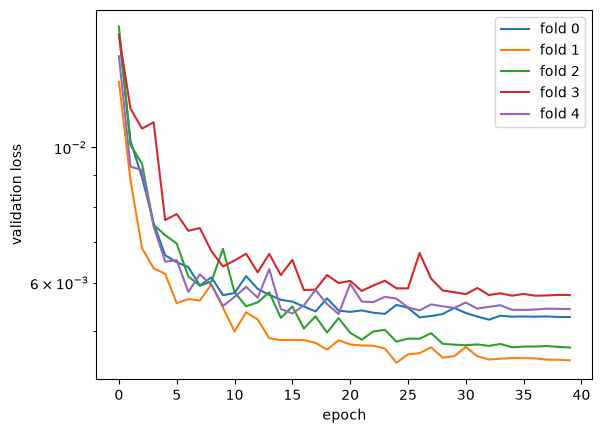

In [10]:
for k, curve in enumerate(curves):
    plt.plot(curve, label=f"fold {k}")
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("validation loss")
plt.legend()
plt.show()

## Submission

In [11]:
submission = physical(predict_ensemble(ensemble, features(test_inputs)))
submission.insert(0, "z_mm", test_inputs.z_mm.to_numpy())
submission.insert(0, "config", test_inputs.config.to_numpy())
submission.to_csv("submission_ood.csv", index=False)
print(f"wrote submission_ood.csv ({len(submission):,} rows)")

wrote submission_ood.csv (40,341 rows)


## Save for the Hopsworks registry

In [12]:
name = f"lsr_{TASK}_mlp"
path = f"models/{name}"
os.makedirs(path, exist_ok=True)
for seed, model in enumerate(ensemble):
    torch.save(model["net"].state_dict(), f"{path}/model_seed{seed}.pt")
    np.savez(f"{path}/scaler_seed{seed}.npz", x_mean=model["scaler"].mean_, x_std=model["scaler"].scale_,
             y_mean=model["y_mean"], y_std=model["y_std"])

scores = score(predict_ensemble(ensemble, features(test)), test)
metrics = {}
for t in TARGETS:
    metrics[f"holdout_r2_{t}"] = round(scores[t], 4)
metrics["holdout_mean_r2"] = round(scores["mean"], 4)
metrics["cv_mean_r2"] = round(float(cv.loc["mean", "mlp"]), 4)
metrics["ood_above_cut_mean_r2"] = round(gaps["mlp ensemble"]["above cut"], 4)
metrics["ood_gap"] = round(gaps["mlp ensemble"]["gap"], 4)
json.dump({"task": TASK, "model": "mlp", "features": FEATURES, "targets": TARGETS, "metrics": metrics},
          open(f"{path}/meta.json", "w"), indent=1)
metrics

{'holdout_r2_E_MeV': 0.9978,
 'holdout_r2_q_pC': 0.9987,
 'holdout_r2_dE_pct': 0.9834,
 'holdout_r2_emit_um': 0.9838,
 'holdout_r2_div_mrad': 0.9889,
 'holdout_r2_sigz_um': 0.9757,
 'holdout_mean_r2': 0.988,
 'cv_mean_r2': 0.9864,
 'ood_above_cut_mean_r2': np.float64(0.963),
 'ood_gap': np.float64(0.025)}

## Comparison

In [13]:
table = pd.DataFrame({
    "rf": score(rf.predict(features(test)), test),
    "xgb": score(xgb.predict(features(test)), test),
    "mlp": score(predict_mlp(mlp, features(test)), test),
    "ensemble": score(predict_ensemble(ensemble, features(test)), test),
    "ensemble, drift": score(predict_ensemble(ensemble, features(test)), test, zone="drift"),
    "internal emulator (medium bar)": {"E_MeV": 0.9633, "q_pC": 0.9331, "dE_pct": 0.8092, "emit_um": 0.8610, "div_mrad": 0.9469, "sigz_um": 0.8623, "mean": 0.8960},
})
table.T[TARGETS + ["mean"]].round(3)

,E_MeV,q_pC,dE_pct,emit_um,div_mrad,sigz_um,mean
rf,0.940,0.832,0.780,0.701,0.852,0.803,0.818
xgb,0.971,0.929,0.812,0.895,0.968,0.894,0.911
mlp,0.997,0.998,0.981,0.983,0.988,0.977,0.987
ensemble,0.998,0.999,0.983,0.984,0.989,0.976,0.988
"ensemble, drift",0.998,1.000,0.982,NaN,NaN,0.969,0.987
internal emulator (medium bar),0.963,0.933,0.809,0.861,0.947,0.862,0.896
